In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,radar_factory

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=1):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

def OS_model(t, *args):
    T_0,T_peak,T_os,t_up,t_plat,t_down=args
    out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up
    out = np.concatenate([out,[T_peak]*len(t[(t_up<t)&(t<=t_up+t_plat)])])
    out = np.concatenate([out, T_peak - (t[(t_up+t_plat<t)&(t<=t_down+t_up+t_plat)]-t_up-t_plat)*(T_peak-T_os)/(t_down)])
    return np.concatenate([out, [T_os]*(len(t)-len(out))])

# Loading data

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [3]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

TEs=df_TEs.index.values

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Running simulations

In [4]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|██████████████████████████████████████| 450/450 [00:00<00:00, 10522.30it/s]


## Fitting PROVIDE to the 6-parameter tipmip

In [5]:
t_ref=2015
xdata = np.arange(t_ref,2301)-t_ref
popt = []
for s in scenarios:
    temp=df[s].to_numpy()
    ydata=df[s].to_numpy()[t_ref-1850:]
    T_ref=temp[t_ref-1850]
    T_max=temp.max()
    p, pcov = curve_fit(OS_model, xdata, ydata,
                           p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                           bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                     [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )
    popt+=[p]
popt=np.array(popt)
popt.shape

par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   

In [6]:
popt_normed = popt/popt.max(axis=0)

In [7]:
D.shape

(15, 500, 9, 451)

In [8]:
def local_safety(D,safety_threshold=0.1,
              dimension_kw=dict(year=-1,sample=1)):
    return np.max(D,axis=dimension_kw['year'],keepdims=True).mean(axis=dimension_kw['sample'],keepdims=True)<=safety_threshold
def global_safety(D,safety_threshold=0.1,
                  dimension_kw=dict(year=-1,sample=1,tipping_element=2)):
    return local_safety(D,safety_threshold=0.1,
                  dimension_kw=dimension_kw).mean(axis=dimension_kw['tipping_element'],keepdims=True)

In [37]:
np.squeeze(global_safety(D,dimension_kw=dict(year=-1,sample=1,tipping_element=2)))

array([0.44444444, 0.44444444, 0.66666667, 0.77777778, 0.66666667,
       0.88888889, 0.88888889, 0.88888889, 0.88888889, 0.88888889,
       0.88888889, 0.88888889, 0.88888889, 0.88888889, 0.88888889])

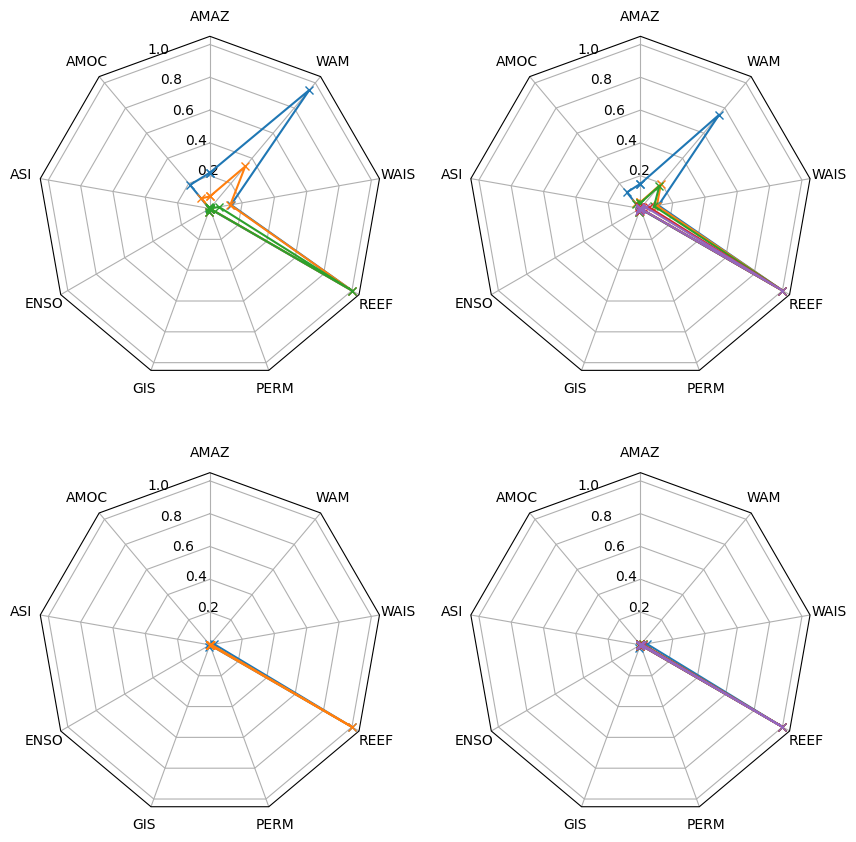

In [57]:
dimension_kw=dict(year=-1,sample=1,tipping_element=2)
metric = np.squeeze(np.max(D,axis=dimension_kw['year'],keepdims=True).mean(axis=dimension_kw['sample'],keepdims=True))

N = len(TEs)
theta = radar_factory(N, frame='polygon')
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,10),sharex=True,sharey=False,
                     subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.20, top=0.85, bottom=0.05)

for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    # axs[int(PA_compliant(moving_avg(temp))), 
    #     int(OS_ref(temp,ref=1.5))].scatter(theta,metric[i,:],marker='x',s=100)
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(theta,metric[i,:],marker='x')
for i in range(4):
    axs[i//2,i%2].set_xticks(theta,TEs)
    # axs[i//2,i%2].set_ylim(0,1)

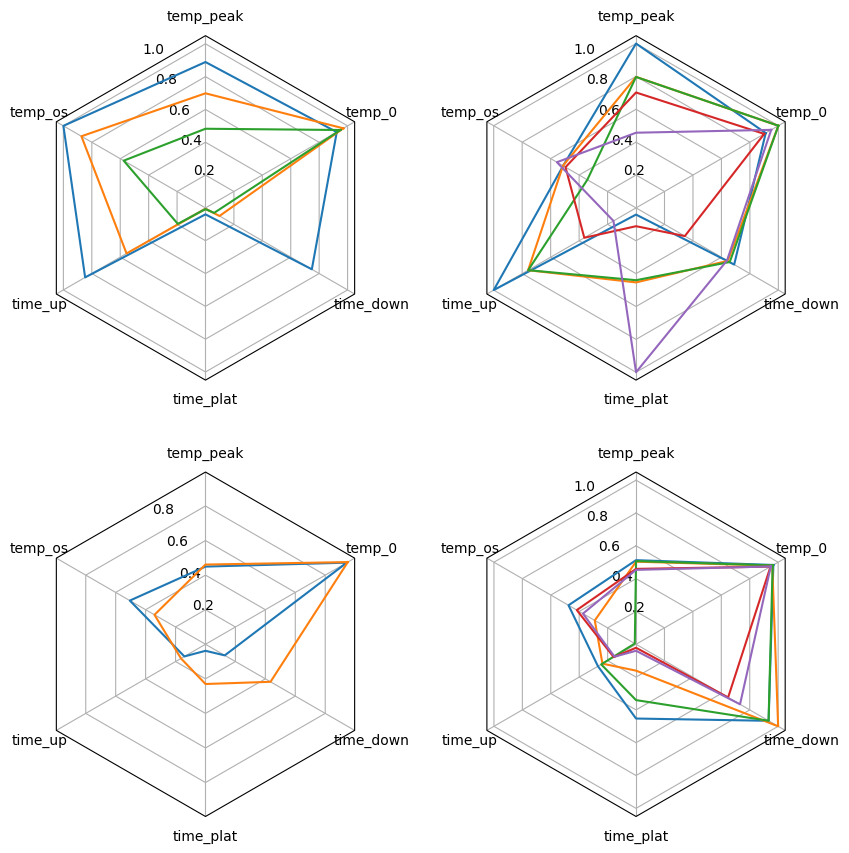

In [25]:
N = 6
theta = radar_factory(N, frame='polygon')
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,10),sharex=True,sharey=False,
                     subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.20, top=0.85, bottom=0.05)

# axs[0,0].set_xlim(t_ref,2300)
reorder = [5,0,1,2,3,4]
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(theta[reorder], popt_normed[i,:])

for i in range(4):
    axs[i//2,i%2].set_xticks(theta[reorder],par_files)

In [17]:
len(theta)

6